In [156]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

file_path = "steel_data.csv"

df = pd.read_csv(file_path)
df.drop(columns=["Sl. No."], inplace=True) # Removing sample number column
pd.set_option('display.max_columns', None)

---
# **Exploratory Data Analysis**


In [157]:
# Variable abbreviation table
vars = pd.DataFrame([
    ("C",       "% Carbon"), ("Si",      "% Silicon"), ("Mn",      "% Manganese"), ("P",       "% Phosphorus"), ("S",       "% Sulphur"), ("Ni",      "% Nickel"), ("Cr",      "% Chromium"), ("Cu",      "% Copper"), ("Mo",      "% Molybdenum"), ("NT",      "Normalizing Temperature"), ("THT",     "Through Hardening Temperature"), ("THt",     "Through Hardening Time"), ("THQCr",   "Cooling Rate for Through Hardening"), ("CT",      "Carburization Temperature"), ("Ct",      "Carburization Time"), ("DT",      "Diffusion Temperature"), ("Dt",      "Diffusion time"), ("QmT",     "Quenching Media Temperature (for Carburization)"), ("TT",      "Tempering Temperature"), ("Tt",      "Tempering Time"), ("TCr",     "Cooling Rate for Tempering"), ("RedRatio","Reduction Ratio (Ingot to Bar)"), ("dA",      "Area Proportion of Inclusions Deformed by Plastic Work"), ("dB",      "Area Proportion of Inclusions Occurring in Discontinuous Array"), ("dC",      "Area Proportion of Isolated Inclusions"), ("Fatigue", "Rotating Bending Fatigue Strength (10^7 Cycles)"),
], columns=["Abbreviation", "Property Details"])

display(vars)

# Checking shape of dataset
print(df.shape, "\n")

# Checking first 3, random 3, and last 3 observations
display(pd.concat([df.head(3), df.sample(3, random_state=42), df.tail(3)]))

# Converting df dtypes all to float since all vars are numerical
df = df.astype(float)
df.info()

,Abbreviation,Property Details
0,C,% Carbon
1,Si,% Silicon
2,Mn,% Manganese
3,P,% Phosphorus
4,S,% Sulphur
5,Ni,% Nickel
6,Cr,% Chromium
7,Cu,% Copper
8,Mo,% Molybdenum
9,NT,Normalizing Temperature


(437, 26) 



,NT,THT,THt,THQCr,CT,Ct,DT,Dt,QmT,TT,Tt,TCr,C,Si,Mn,P,S,Ni,Cr,Cu,Mo,RedRatio,dA,dB,dC,Fatigue
0,885,30,0,0,30,0.0,30.000,0.0,30,30,0,0.0,0.26,0.21,0.44,0.017,0.022,0.01,0.02,0.01,0.00,825,0.070,0.020,0.040,232
1,885,30,0,0,30,0.0,30.000,0.0,30,30,0,0.0,0.25,0.18,0.44,0.009,0.017,0.08,0.12,0.08,0.00,610,0.110,0.000,0.040,235
2,885,30,0,0,30,0.0,30.000,0.0,30,30,0,0.0,0.26,0.27,0.43,0.008,0.015,0.02,0.03,0.01,0.00,1270,0.070,0.020,0.000,235
395,930,30,0,0,930,540.0,850.000,15.0,140,160,120,0.5,0.21,0.29,0.62,0.015,0.016,1.62,0.59,0.07,0.21,440,0.008,0.000,0.000,1054
78,845,845,30,24,30,0.0,30.000,0.0,30,650,60,24.0,0.45,0.25,0.79,0.011,0.025,0.12,0.04,0.15,0.00,610,0.090,0.000,0.040,398
278,870,845,30,8,30,0.0,30.000,0.0,30,650,60,24.0,0.46,0.30,1.49,0.014,0.008,0.10,0.26,0.10,0.00,1100,0.030,0.000,0.000,460
434,930,30,0,0,930,340.2,895.812,70.2,60,200,120,0.5,0.21,0.31,0.81,0.012,0.019,0.06,1.17,0.07,0.17,690,0.080,0.000,0.000,1104
435,930,30,0,0,930,340.2,895.812,70.2,60,200,120,0.5,0.21,0.26,0.65,0.015,0.024,0.02,0.91,0.01,0.15,240,0.050,0.010,0.000,1008
436,930,30,0,0,930,340.2,895.812,70.2,60,200,120,0.5,0.18,0.25,0.79,0.016,0.015,0.07,1.08,0.08,0.15,530,0.017,0.004,0.008,882


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 437 entries, 0 to 436
Data columns (total 26 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   NT        437 non-null    float64
 1   THT       437 non-null    float64
 2   THt       437 non-null    float64
 3   THQCr     437 non-null    float64
 4   CT        437 non-null    float64
 5   Ct        437 non-null    float64
 6   DT        437 non-null    float64
 7   Dt        437 non-null    float64
 8   QmT       437 non-null    float64
 9   TT        437 non-null    float64
 10  Tt        437 non-null    float64
 11  TCr       437 non-null    float64
 12  C         437 non-null    float64
 13  Si        437 non-null    float64
 14  Mn        437 non-null    float64
 15  P         437 non-null    float64
 16  S         437 non-null    float64
 17  Ni        437 non-null    float64
 18  Cr        437 non-null    float64
 19  Cu        437 non-null    float64
 20  Mo        437 non-null    float6

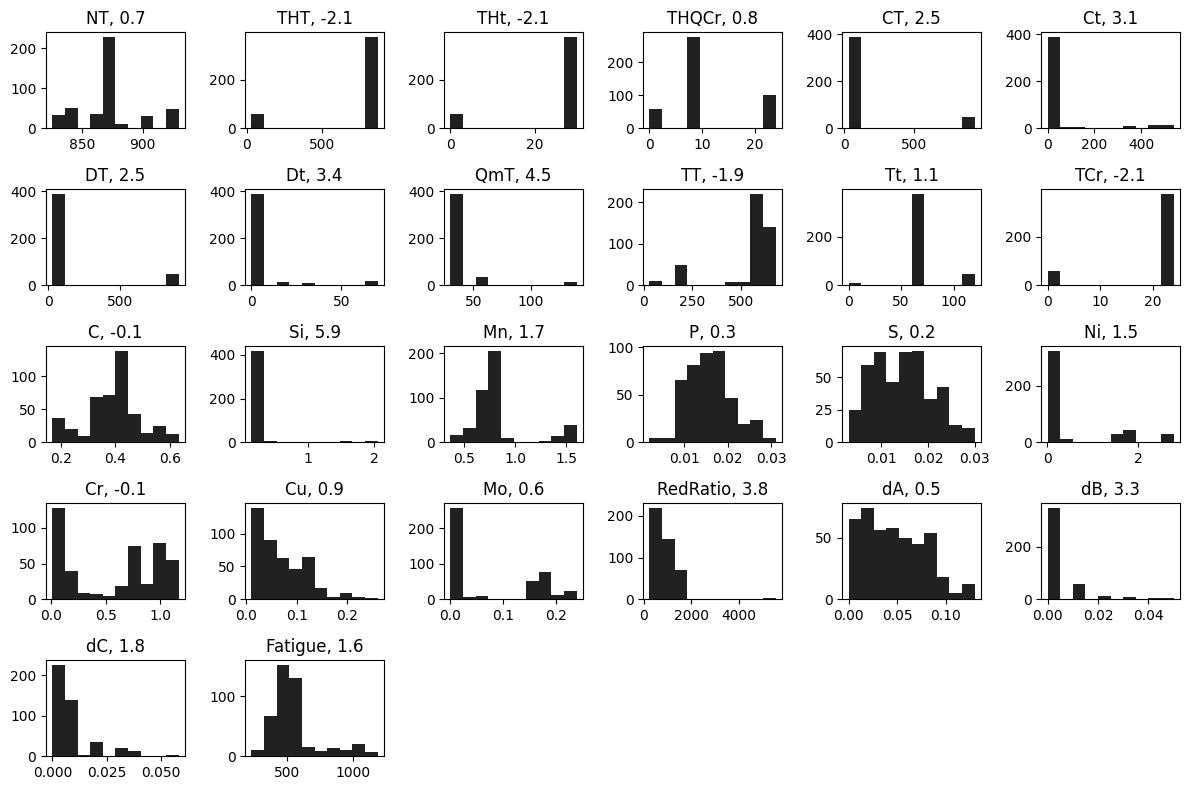

In [158]:
var_count = len(df.columns)
ncols = 6
nrows = 5

# Histogram plot for 26 variables
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12,8))
axes_flat = axes.flatten()

for i, col_name in enumerate(df.columns[:var_count]):
    axes_flat[i].hist(df[col_name], color='#212121')
    axes_flat[i].set_title(col_name + ", " + str(df[col_name].skew().round(1)))

for j in range(var_count, len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout()
plt.show()

,NT,THT,THt,THQCr,CT,Ct,DT,Dt,QmT,TT,Tt,TCr,C,Si,Mn,P,S,Ni,Cr,Cu,Mo,RedRatio,dA,dB,dC,Fatigue
count,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00,437.00
mean,872.30,737.64,25.95,10.65,128.86,40.50,123.70,4.84,35.49,536.84,65.08,20.81,0.39,0.30,0.82,0.02,0.01,0.52,0.57,0.07,0.07,923.63,0.05,0.00,0.01,552.90
std,26.21,280.04,10.26,7.84,281.74,126.92,267.13,15.70,19.42,164.10,21.48,8.07,0.10,0.25,0.28,0.01,0.01,0.85,0.41,0.05,0.09,576.62,0.03,0.01,0.01,186.63
min,825.00,30.00,0.00,0.00,30.00,0.00,30.00,0.00,30.00,30.00,0.00,0.00,0.17,0.16,0.37,0.00,0.00,0.01,0.01,0.01,0.00,240.00,0.00,0.00,0.00,225.00
25%,865.00,845.00,30.00,8.00,30.00,0.00,30.00,0.00,30.00,550.00,60.00,24.00,0.34,0.24,0.70,0.01,0.01,0.02,0.12,0.02,0.00,590.00,0.02,0.00,0.00,448.00
50%,870.00,845.00,30.00,8.00,30.00,0.00,30.00,0.00,30.00,600.00,60.00,24.00,0.40,0.26,0.76,0.02,0.02,0.06,0.71,0.06,0.00,740.00,0.04,0.00,0.00,505.00
75%,870.00,855.00,30.00,8.00,30.00,0.00,30.00,0.00,30.00,650.00,60.00,24.00,0.43,0.29,0.80,0.02,0.02,0.46,0.98,0.10,0.17,1228.00,0.07,0.00,0.01,578.00
max,930.00,865.00,30.00,24.00,930.00,540.00,903.33,70.20,140.00,680.00,120.00,24.00,0.63,2.05,1.60,0.03,0.03,2.78,1.17,0.26,0.24,5530.00,0.13,0.05,0.06,1190.00


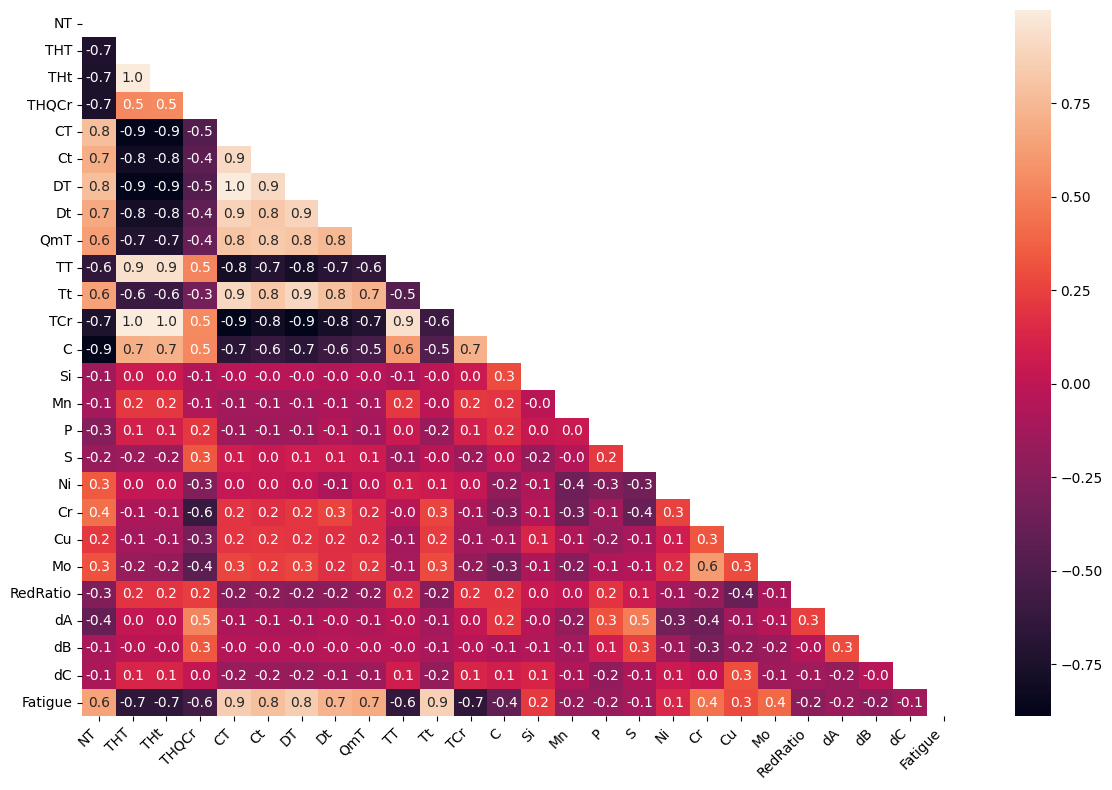

In [159]:
# Quick descriptive stats
display(df.describe().round(2))

corr = df.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

fig_1, ax_1 = plt.subplots(1,1, figsize=(12,8))
ax_1 = sns.heatmap(corr, ax=ax_1, annot=True, fmt='.1f', mask=mask)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---
# **Splitting the dataset and instantiating different linear models**

In [160]:
# Splitting of training and test dataset
target = 'Fatigue'
feature = [col for col in df.columns if col not in target]

X = df[feature]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [161]:
# Instantiating different linear models

# Ordinary Least Squares Regression
model_lr = make_pipeline(StandardScaler(), LinearRegression())

# Ridge Regularized CV (lambda hyperparameter to be determined)
model_ridge = make_pipeline(StandardScaler(), RidgeCV(cv=5))

# Lasso Regularized CV
model_lasso = make_pipeline(StandardScaler(), LassoCV(max_iter=100000, cv=5))

# Elastic CV
model_elastic = make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0], cv=5, max_iter=100000))

# Creating model list
model_list = [model_lr, model_ridge, model_lasso, model_elastic]

---
# **Functions**

In [162]:
# Model Fit Function
def fit_model(model_list, X_train, y_train):
    """
    fits every model in the model_list

    args: a list containing the instantiated linear models
    X_train, y_train: training set
    """

    for model in model_list:

        model.fit(X_train, y_train)

    print("Model fitting done.")




# Metrics Computation Function
def compute_metrics(model_list, X_train, y_train, X_test, y_test, y_transformed=False):
    """
    returns a dataframe of MAE, RMSE, and R2 score for each model in the given model_list

    args:
    model_list: a list containing the instantiated linear models
    X_train, y_train, X_test, y_test: the conventional datasets obtained from train_test_split
    """
    score_list = []

    for model in model_list:

        if y_transformed == False: # Normal or Unexponentiated set of targets
            y_train_i = y_train
            y_test_i = y_test
            y_train_pred_i = model.predict(X_train)
            y_test_pred_i = model.predict(X_test)

        else: # Exponentiated set of targets
            y_train_i = np.exp(y_train)
            y_test_i = np.exp(y_test)
            y_train_pred_i = np.exp(model.predict(X_train))
            y_test_pred_i = np.exp(model.predict(X_test))

        score_list.append({
          "Model": str(model[1]).split("(")[0], # Access the model's name
          "MAE_train": mean_absolute_error(y_train_i, y_train_pred_i),
          "MAE_test": mean_absolute_error(y_test_i, y_test_pred_i),
          "RMSE_train": root_mean_squared_error(y_train_i, y_train_pred_i),
          "RMSE_test": root_mean_squared_error(y_test_i, y_test_pred_i),
          "R2_train": r2_score(y_train_i, y_train_pred_i),
          "R2_test": r2_score(y_test_i, y_test_pred_i)
        })

    score_df = pd.DataFrame(score_list)
    score_df['MAE_diff'] = score_df['MAE_test'] - score_df['MAE_train']
    score_df['RMSE_diff'] = score_df['RMSE_test'] - score_df['RMSE_train']
    score_df['R2_diff'] = score_df['R2_test'] - score_df['R2_train']

    return score_df.round(3)




# Feature Importance Computation Function
def compute_feature_importance(model_list, X_train):
    """
    returns a dataframe feature importance for each model in the list of linear models

    args:
    model_list: a list containing the instantiated model
    X_train: from the train_test_split
    """
    feature_list = [X_train.columns]
    model_list_str = []

    for model in model_list:
        model_str = str(model[1]).split("(")[0] + "_coef"
        model_list_str.append(model_str)

        feature_list.append(model[1].coef_)

    feature_df = pd.DataFrame(feature_list).transpose()
    feature_df.columns = ['Feature'] + model_list_str

    return feature_df.round(3)

---
# **Model Fitting and Inference using the original unaltered dataset**

In [163]:
# Fitting training data to models in model_list
fit_model(model_list, X_train, y_train)

# Computing metrics of each model
df_metrics = compute_metrics(model_list, X_train, y_train, X_test, y_test)
display(df_metrics)

Model fitting done.


,Model,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test,MAE_diff,RMSE_diff,R2_diff
0,LinearRegression,22.568,24.866,31.378,32.162,0.97,0.975,2.298,0.783,0.005
1,RidgeCV,22.667,24.968,31.499,32.321,0.97,0.975,2.301,0.822,0.005
2,LassoCV,22.471,24.489,31.534,31.754,0.97,0.976,2.017,0.221,0.006
3,ElasticNetCV,22.576,24.658,31.565,31.923,0.97,0.975,2.082,0.359,0.005


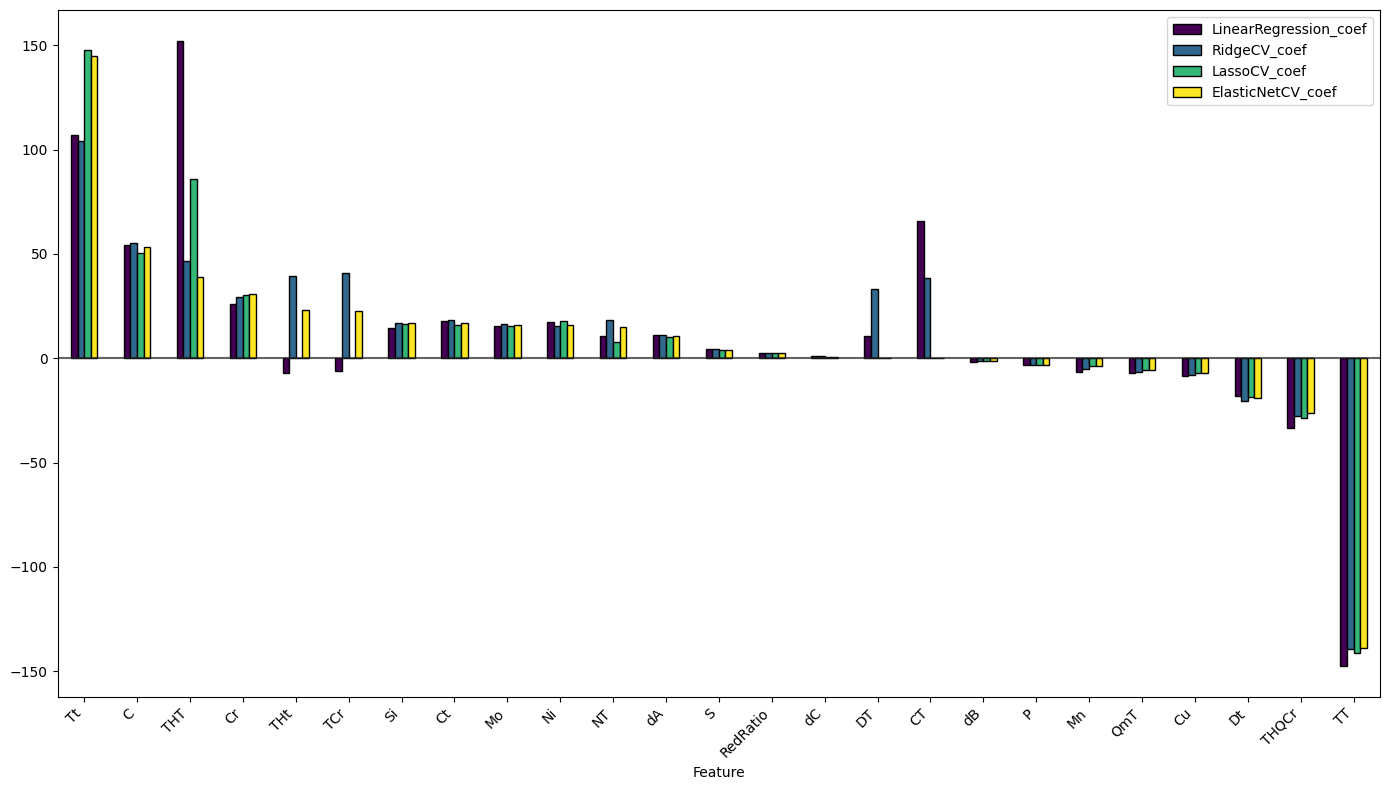

In [164]:
# Feature importance
df_feature_imp = compute_feature_importance(model_list, X_train).sort_values(by='ElasticNetCV_coef', ascending=False)

# Visualizing feature importance per model
fig_2, ax_2 = plt.subplots(1,1,figsize=(14,8))
df_feature_imp.plot(kind='bar', x='Feature', ax=ax_2, cmap='viridis', edgecolor='black')
ax_2.axhline(y=0, color='#212121', alpha=0.7)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

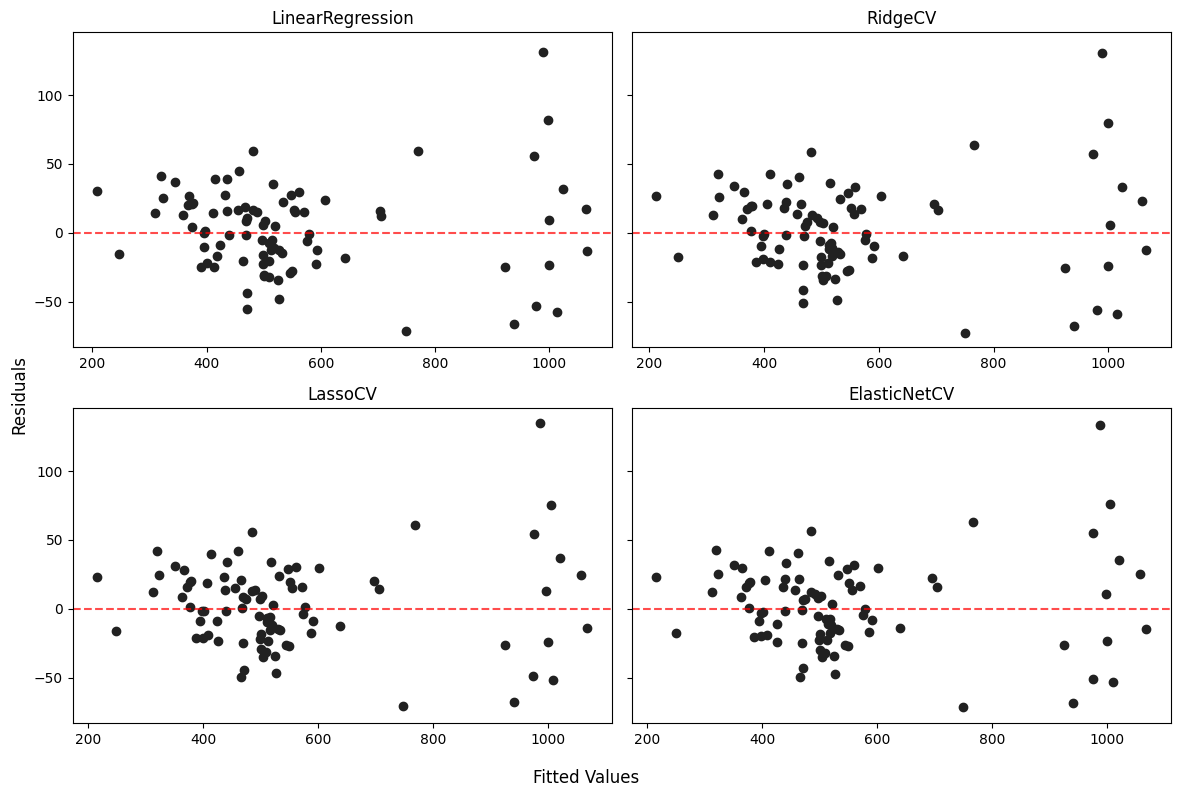

In [165]:
# Creating residuals vs. fitted plot
fig_3, ax_3 = plt.subplots(2,2, figsize=(12,8), sharey=True)

for i, ax in enumerate(ax_3.flat):
    preds = model_list[i].predict(X_test)
    resids = y_test - preds

    ax.scatter(x=preds, y=resids, color='#212121')
    ax.axhline(y=0, color='r', linestyle='--', alpha=0.7)

    ax.set_title(str(model_list[i][1]).split("(")[0])

fig_3.supxlabel("Fitted Values")
fig_3.supylabel("Residuals")

plt.tight_layout()
plt.show()

---
# **Model Fitting and Inference using feature-engineered dataset**
Added Carbon Equivalent (CEq) as feature, and transformed Fatigue to log(Fatigue)

In [166]:
# Feature Engineering
df_e = df.copy() # df_e is df that is to be engineered

# Carbon Equivalent (0.17 are also considered in the IIW Formula for simplicity)
df_e['CEq'] = df_e['C'] + df_e['Mn']/6 + (df_e['Cr'] + df_e['Mo'])/5 + (df_e['Ni'] + df_e['Cu'])/15

# Log(Fatigue)
df_e['logFatigue'] = np.log(df_e['Fatigue'])

In [167]:
target_df_e = 'logFatigue'
feature_df_e = [col for col in df_e.columns if col not in (target_df_e, 'Fatigue')]

X_e = df_e[feature_df_e]
y_e = df_e[target_df_e]

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_e, y_e, test_size=0.2, random_state=42)

In [168]:
# Fitting training data to models in model_list (feature engineered data)
fit_model(model_list, X_train_e, y_train_e)

# Computing metrics of each model (feature engineered data)
df_metrics_e = compute_metrics(model_list, X_train_e, y_train_e, X_test_e, y_test_e, y_transformed=True) # y_transformed set to True since the target y is transformed to be log(y)
display(df_metrics_e)

Model fitting done.


,Model,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test,MAE_diff,RMSE_diff,R2_diff
0,LinearRegression,21.120,20.339,29.928,28.802,0.973,0.980,-0.781,-1.126,0.007
1,RidgeCV,21.135,20.142,30.044,28.542,0.973,0.980,-0.994,-1.502,0.008
2,LassoCV,21.160,19.894,30.366,28.364,0.972,0.981,-1.266,-2.002,0.008
3,ElasticNetCV,21.231,19.934,30.453,28.454,0.972,0.980,-1.297,-1.999,0.008


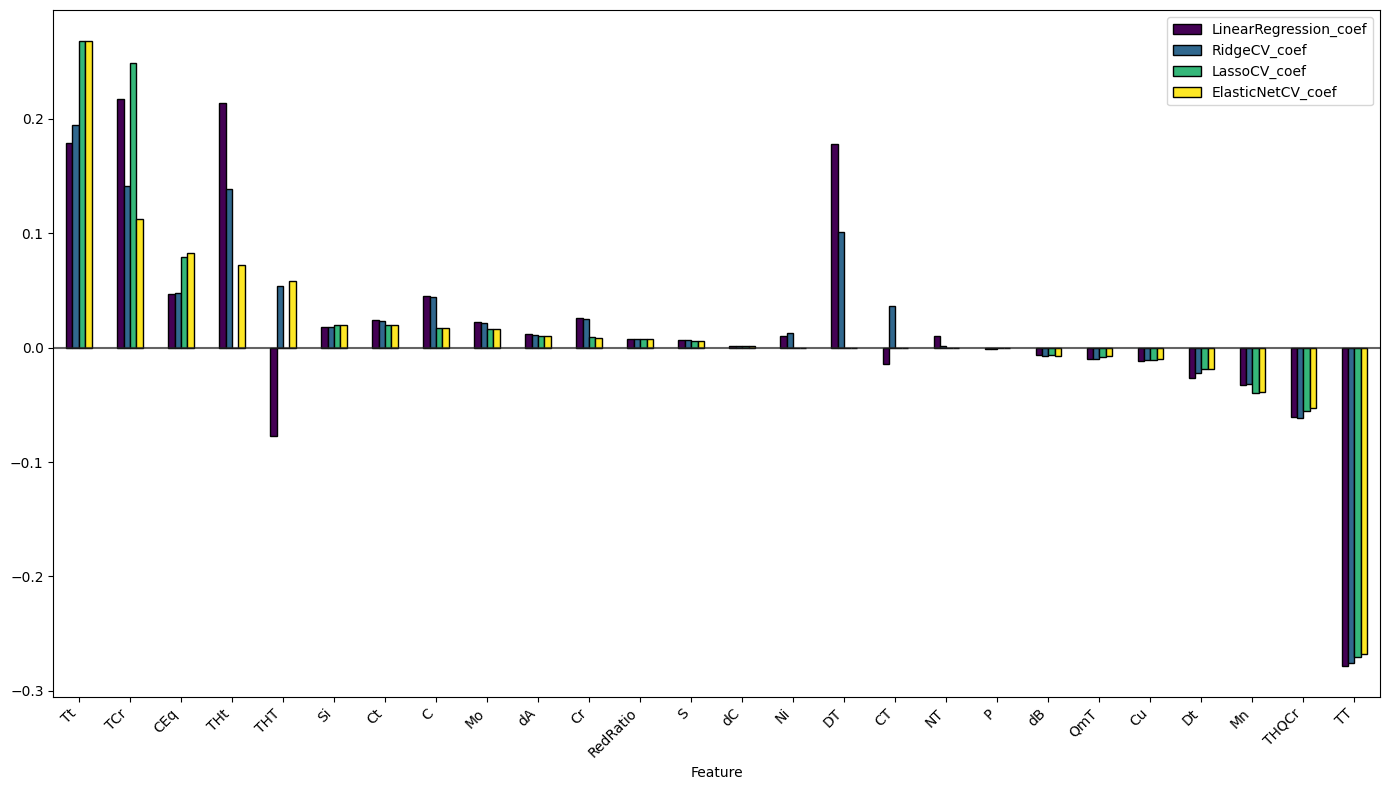

In [169]:
# Feature importance
df_feature_imp_e = compute_feature_importance(model_list, X_train_e).sort_values(by='ElasticNetCV_coef', ascending=False)

# Visualizing feature importance per model
fig_4, ax_4 = plt.subplots(1,1,figsize=(14,8))
df_feature_imp_e.plot(kind='bar', x='Feature', ax=ax_4, cmap='viridis', edgecolor='black')
ax_4.axhline(y=0, color='#212121', alpha=0.7)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

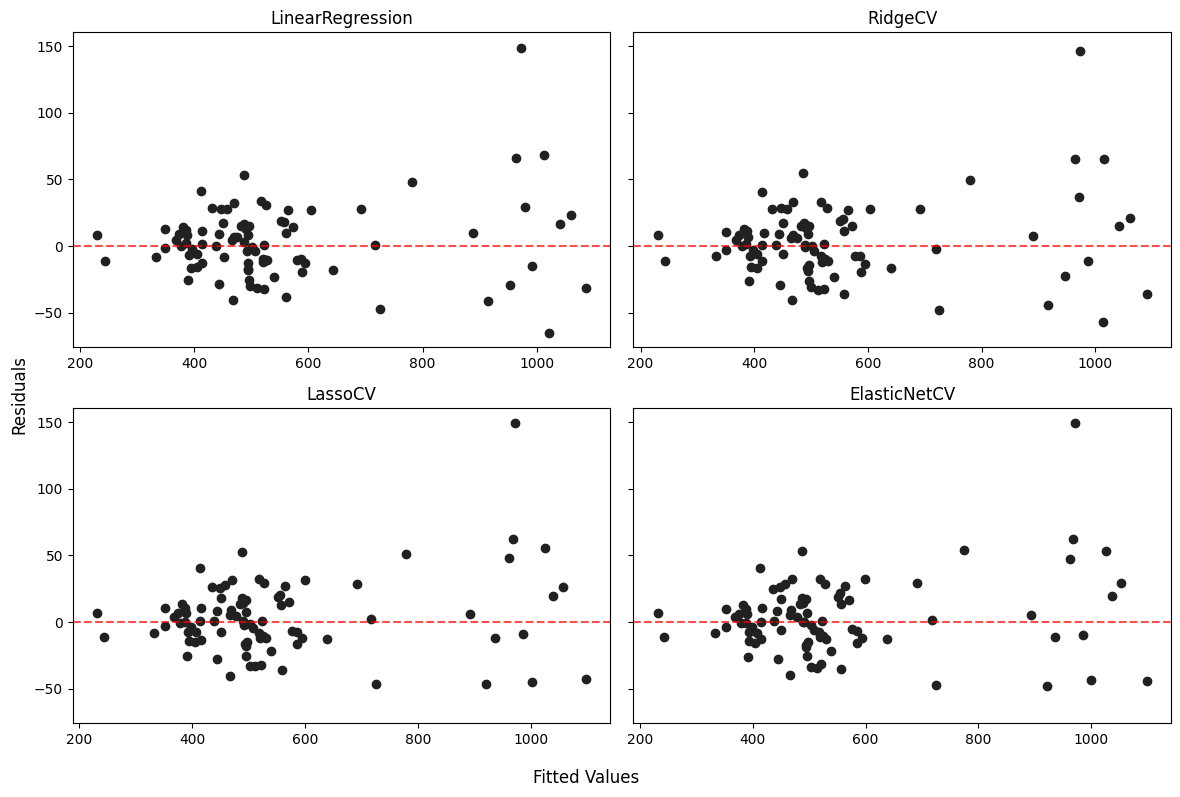

In [170]:
# Creating residuals vs. fitted plot for feature-engineered df
fig_5, ax_5 = plt.subplots(2,2, figsize=(12,8), sharey=True)

true = np.exp(y_test_e)

for i, ax in enumerate(ax_5.flat):
    preds = np.exp(model_list[i].predict(X_test_e))
    resids = true - preds

    ax.scatter(x=preds, y=resids, color='#212121')
    ax.axhline(y=0, color='r', linestyle='--', alpha=0.7)

    ax.set_title(str(model_list[i][1]).split("(")[0])

fig_5.supxlabel("Fitted Values")
fig_5.supylabel("Residuals")

plt.tight_layout()
plt.show()